# 第7回　汎化，正則化，評価設計

「実験結果はいつ信用できるか」を，小さなデータで体験する．指標の計算，閾値，過学習，データリーク，複数シード，較正を扱う．

| 節 | テーマ |
|---|---|
| §1 | 混同行列と指標 |
| §2 | 閾値と PR・ROC 曲線 |
| §3 | 過学習と Early Stopping |
| §4 | グループリーク |
| §5 | アブレーションと複数シード |
| §6 | 較正 |

```{admonition} この章の使い方
:class: tip
ページ右上のロケットのボタンから Colab で開くか，[環境構築](setup.md) に従って手元で実行する．セルは **上から順に** 実行する．
**やってみよう** は `# TODO` の行を書き換えて再実行する（先に結果を予想してから）．「補助コード」と書いたセルは本題ではない補助の実装で，中身は読まなくてよい（折りたたんである）．
詳しくは [ノートブックの使い方](usage.md)．
```

環境：Python 3 ＋ NumPy ＋ Matplotlib（PyTorch は使わない）．

In [1]:
import numpy as np
import matplotlib.pyplot as plt
try:
    import matplotlib_fontja                       # 図の日本語フォント（pip install matplotlib-fontja）
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=False)
    import matplotlib_fontja
np.set_printoptions(precision=4, suppress=True)

## §1 混同行列と指標

2 クラス分類の結果は 4 つの数にまとまる：TP（真陽性）・FP（偽陽性）・FN（偽陰性）・TN（真陰性）．講義の数値例：100 件中 10 件が異常（陽性）．モデルは異常 8 件を見つけ（TP=8），正常 4 件を異常と誤り（FP=4），異常 2 件を見逃した（FN=2）．

In [2]:
def metrics(TP, FP, FN, TN):
    acc = (TP + TN) / (TP + FP + FN + TN)
    precision = TP / (TP + FP) if TP + FP > 0 else 0.0
    recall = TP / (TP + FN) if TP + FN > 0 else 0.0
    f1 = 2 * TP / (2 * TP + FP + FN)
    return dict(accuracy=acc, precision=precision, recall=recall, f1=f1)

def show(m):
    return f"正解率 {m['accuracy']:.2f}  適合率 {m['precision']:.2f}  再現率 {m['recall']:.2f}  F1 {m['f1']:.2f}"

print("講義の数値例      :", show(metrics(TP=8, FP=4, FN=2, TN=86)), "  （適合率 = 8/12，再現率 = 8/10，F1 = 16/22）")
print("全件を正常と答える:", show(metrics(TP=0, FP=0, FN=10, TN=90)))

講義の数値例      : 正解率 0.94  適合率 0.67  再現率 0.80  F1 0.73   （適合率 = 8/12，再現率 = 8/10，F1 = 16/22）
全件を正常と答える: 正解率 0.90  適合率 0.00  再現率 0.00  F1 0.00


読み方：全件を「正常」と答えても正解率は 0.90．異常を 1 件も拾えていない（再現率 0）のに，正解率では悪く見えない．

**やってみよう 1-1**　TP=30，FP=10，FN=20，TN=940 のとき，4 つの指標はいくらか．先に手で計算してから実行する．

In [3]:
print(show(metrics(TP=30, FP=10, FN=20, TN=940)))   # TODO: 閾値を下げた後の TP=40, FP=40, FN=10, TN=910 に変えて実行する

正解率 0.97  適合率 0.75  再現率 0.60  F1 0.67


閾値を下げて TP と FP がともに増えると，再現率は上がり，適合率は下がる（次の §2）．

## §2 閾値と PR・ROC 曲線講義の 20 件（陽性 6 件，陰性 14 件）の予測スコアを使う．閾値を動かすと，拾える陽性と誤警報の両方が変わる．

In [4]:
score_pos = np.array([0.90, 0.80, 0.72, 0.60, 0.55, 0.30])                                  # 実際の陽性 6 件
score_neg = np.array([0.75, 0.70, 0.62, 0.52, 0.45, 0.40, 0.35, 0.30, 0.25, 0.20, 0.15, 0.10, 0.08, 0.05])   # 実際の陰性 14 件
scores = np.concatenate([score_pos, score_neg])
labels = np.concatenate([np.ones(6, int), np.zeros(14, int)])

def confusion(threshold):
    pred = scores >= threshold                       # 閾値以上を「陽性」と判定（True/False の配列）
    TP = int(np.sum(pred & (labels == 1))); FP = int(np.sum(pred & (labels == 0)))    # & は「両方が True」
    FN = int(np.sum(~pred & (labels == 1))); TN = int(np.sum(~pred & (labels == 0)))  # ~pred は pred の否定
    return TP, FP, FN, TN

for th in (0.68, 0.50):
    TP, FP, FN, TN = confusion(th)
    m = metrics(TP, FP, FN, TN)
    print(f"閾値 {th}: TP={TP} FP={FP} FN={FN} TN={TN}  適合率 {m['precision']:.2f}  再現率 {m['recall']:.2f}")

閾値 0.68: TP=3 FP=2 FN=3 TN=12  適合率 0.60  再現率 0.50
閾値 0.5: TP=5 FP=4 FN=1 TN=10  適合率 0.56  再現率 0.83


読み方：閾値を 0.68 から 0.50 に下げると，拾えた陽性は 3 → 5（再現率 0.50 → 0.83），誤警報は 2 → 4（適合率 0.60 → 0.56）．

閾値を 1 から 0 まで動かして，（再現率，適合率）の軌跡＝ **PR 曲線**，（偽陽性率 FP/(FP+TN)，真陽性率 TP/(TP+FN)）の軌跡＝ **ROC 曲線** を描き，ROC 曲線の下の面積（**AUC**．1 が最良，0.5 が当てずっぽう）を求める．

ROC 曲線の下の面積 AUC = 0.827


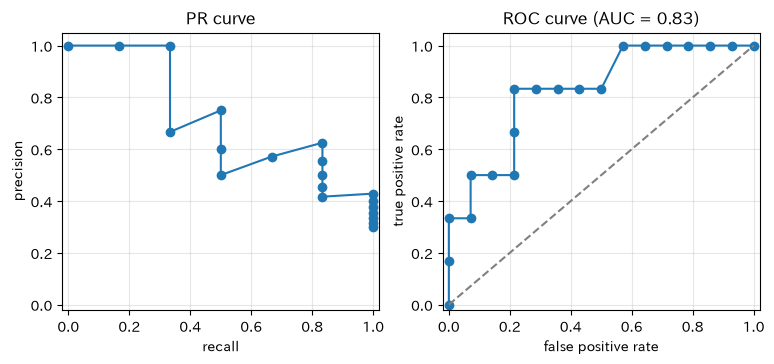

In [5]:
ths = np.sort(np.unique(np.concatenate([scores, [1.01]])))[::-1]      # 出現するスコアを閾値の候補にし，大きい順に並べる
rec, prec, tpr, fpr = [], [], [], []
for th in ths:
    TP, FP, FN, TN = confusion(th)
    rec.append(TP / (TP + FN)); prec.append(TP / (TP + FP) if TP + FP > 0 else 1.0)
    tpr.append(TP / (TP + FN)); fpr.append(FP / (FP + TN))
auc = float(np.sum(np.diff(fpr) * (np.array(tpr[1:]) + np.array(tpr[:-1])) / 2))   # 台形で面積を求める
print(f"ROC 曲線の下の面積 AUC = {auc:.3f}")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].plot(rec, prec, marker='o'); axes[0].set_xlabel('recall'); axes[0].set_ylabel('precision'); axes[0].set_title('PR curve')
axes[1].plot(fpr, tpr, marker='o'); axes[1].plot([0, 1], [0, 1], '--', c='gray'); axes[1].set_xlabel('false positive rate'); axes[1].set_ylabel('true positive rate'); axes[1].set_title(f'ROC curve (AUC = {auc:.2f})')
for ax in axes:
    ax.grid(alpha=0.3); ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.05)
plt.show()

AUC にはもう 1 つの読み方がある：無作為に選んだ陽性 1 件と陰性 1 件で，陽性のスコアの方が高い確率．台形の面積と同じ値（0.827）になる（下の `auc_of` で確かめる）．

**やってみよう 2-1**　陽性の 1 件（スコア 0.30）を 0.95 に書き換えると，AUC はどう変わるか．逆に陰性の 1 件（スコア 0.75）を 0.95 にすると？

In [6]:
def auc_of(score_pos, score_neg):
    """AUC ＝「陽性のスコア > 陰性のスコア」となる組の割合（同点は 0.5 と数える）．"""
    diff = score_pos[:, None] - score_neg[None, :]      # 陽性 × 陰性 の全部の組の差
    return np.mean((diff > 0) + 0.5 * (diff == 0))

print("元の AUC =", auc_of(score_pos, score_neg))
sp = score_pos.copy(); sp[-1] = 0.30       # TODO: 0.95 に書き換える（元は 0.30）
sn = score_neg.copy(); sn[0] = 0.75        # TODO: 0.95 に書き換える（元は 0.75）
print("陽性の 1 件を変えた AUC =", auc_of(sp, score_neg), "  陰性の 1 件を変えた AUC =", auc_of(score_pos, sn))

元の AUC = 0.8273809523809523
陽性の 1 件を変えた AUC = 0.8273809523809523   陰性の 1 件を変えた AUC = 0.8273809523809523


## §3 過学習と Early Stopping

訓練データ 60 点（10 次元の特徴．クラスの違いは最初の 2 次元にだけ出る．15% のラベルが間違い）に，隠れ層 64 ユニット × 2 層の大きな MLP を当てはめる．
検証データは 60 点（正しいラベル）．訓練損失と検証損失の曲線を描き，検証損失が最小になる時点（Early Stopping の止めどき）を求める．

In [7]:
# 補助コード：全結合ネットワーク（中身は読まなくてよい．第3回 §3 の mlp_forward/mlp_backward と同じ計算に，
#       初期化の種類・Dropout・Weight Decay を足したもの）
class MLP:
    def __init__(self, sizes, seed=0, init='he', dropout=0.0):
        self.rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            std = {'he': np.sqrt(2.0 / n_in), 'lecun': np.sqrt(1.0 / n_in), 'normal': 1.0}[init]
            self.W.append(self.rng.normal(0.0, std, (n_out, n_in)))
            self.b.append(np.zeros(n_out))
        self.p = dropout

    def forward(self, X, train=False):
        """順伝播．train=True のときだけ Dropout を掛ける（推論時は全ユニットを使う）．"""
        self.cache = []                       # 逆伝播のために (層への入力, 総入力, Dropout のマスク) を覚える
        z = X
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            u = z @ W.T + b
            mask = None
            if l < len(self.W) - 1:           # 隠れ層：ReLU（＋Dropout）
                z_next = np.maximum(0.0, u)
                if train and self.p > 0:
                    mask = (self.rng.random(z_next.shape) >= self.p) / (1.0 - self.p)   # 残りを 1/(1-p) 倍
                    z_next = z_next * mask
            else:                             # 出力層：ロジット（ソフトマックスの前の値）
                z_next = u
            self.cache.append((z, u, mask))
            z = z_next
        return z

    def loss_and_grads(self, X, y, wd=0.0, train=True):
        """交差エントロピー損失と，全パラメータの勾配．wd は Weight Decay の係数 λ．"""
        logits = self.forward(X, train=train)
        P = softmax(logits)
        M = len(y)
        loss = -np.mean(np.log(P[np.arange(M), y] + 1e-12))
        delta = P.copy(); delta[np.arange(M), y] -= 1.0; delta /= M      # 出力層の誤差信号（予測 − 正解）/M
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for l in reversed(range(len(self.W))):
            z_in, u, _ = self.cache[l]
            gW[l] = delta.T @ z_in + wd * self.W[l]                        # 勾配 ＋ Weight Decay の項 λw
            gb[l] = delta.sum(axis=0)
            if l > 0:
                delta = delta @ self.W[l]                                  # 1 層下へ伝える
                mask_prev = self.cache[l - 1][2]
                if mask_prev is not None:
                    delta = delta * mask_prev
                delta = delta * (self.cache[l - 1][1] > 0)                 # ReLU の傾き
        return loss, gW, gb

    def step(self, gW, gb, lr):
        for l in range(len(self.W)):
            self.W[l] -= lr * gW[l]
            self.b[l] -= lr * gb[l]

    def predict(self, X):
        return np.argmax(self.forward(X, train=False), axis=1)


def softmax(u):
    e = np.exp(u - u.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def cross_entropy(model, X, y):
    P = softmax(model.forward(X, train=False))
    return -np.mean(np.log(P[np.arange(len(y)), y] + 1e-12))


def train(model, Xtr, ytr, Xva, yva, lr=0.1, epochs=300, wd=0.0):
    """全データで勾配を求めて更新（ミニバッチなし）．各エポックの訓練損失・検証損失・検証正解率を返す．"""
    hist = {'train': [], 'val': [], 'val_acc': []}
    for ep in range(epochs):
        loss, gW, gb = model.loss_and_grads(Xtr, ytr, wd=wd, train=True)
        model.step(gW, gb, lr)
        hist['train'].append(cross_entropy(model, Xtr, ytr))
        hist['val'].append(cross_entropy(model, Xva, yva))
        hist['val_acc'].append(np.mean(model.predict(Xva) == yva))
    return hist

検証損失が最小のエポック = 77（検証損失 0.300），最後のエポックの検証損失 = 0.370


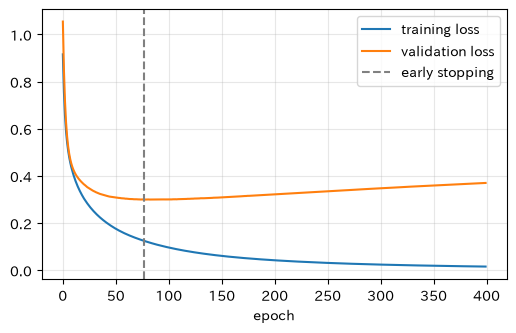

In [8]:
# 補助コード：データを作る関数（中身は読まなくてよい）
def make_data(n, seed, flip=0.15, d=10):
    """2 クラスのデータ．d 次元のうち最初の 2 次元だけが，クラス 1 で +1，クラス 0 で -1 ずれる．各ラベルを確率 flip で反転．"""
    rng = np.random.default_rng(seed)
    y = rng.integers(0, 2, n)
    X = rng.normal(0.0, 1.0, (n, d))
    X[:, :2] += np.where(y[:, None] == 1, 1.0, -1.0)
    wrong = rng.random(n) < flip
    return X, np.where(wrong, 1 - y, y)

Xtr, ytr = make_data(60, seed=1, flip=0.15)     # 訓練：60 点，15% のラベルが間違い
Xva, yva = make_data(60, seed=2, flip=0.0)      # 検証：60 点
model = MLP([10, 64, 64, 2], seed=0)
h = train(model, Xtr, ytr, Xva, yva, lr=0.05, epochs=400)
best = int(np.argmin(h['val']))
print(f"検証損失が最小のエポック = {best}（検証損失 {h['val'][best]:.3f}），最後のエポックの検証損失 = {h['val'][-1]:.3f}")
plt.figure(figsize=(6, 3.5))
plt.plot(h['train'], label='training loss'); plt.plot(h['val'], label='validation loss')
plt.axvline(best, ls='--', c='gray', label='early stopping'); plt.xlabel('epoch'); plt.legend(); plt.grid(alpha=0.3); plt.show()

読み方：訓練損失は下がり続けるが，検証損失は途中（点線）から上がる（過学習）．点線の時点で止めるのが Early Stopping．

**やってみよう 3-1（実行して読む）**　止めどきを決めた検証損失の値を，そのまま最終性能として報告してよいか．下のセルで，止めどきのモデルを，(a) 選択に使った検証データ，(b) 同じ 60 点でも選択に使っていない別の検証データ，(c) テストデータ（2,000 点）で測る．

In [9]:
Xva2, yva2 = make_data(60, seed=4, flip=0.0)        # 選択に使っていない，同じ大きさの検証データ
Xte, yte = make_data(2000, seed=3, flip=0.0)        # テスト：止めどきの選択に使っていないデータ
model = MLP([10, 64, 64, 2], seed=0)
train(model, Xtr, ytr, Xva, yva, lr=0.05, epochs=best + 1)   # エポックは 0 から数えるので，best 番目まで訓練するには +1
print(f"(a) 選択に使った検証損失 {cross_entropy(model, Xva, yva):.3f}   (b) 別の検証データ {cross_entropy(model, Xva2, yva2):.3f}   (c) テスト損失 {cross_entropy(model, Xte, yte):.3f}")

(a) 選択に使った検証損失 0.300   (b) 別の検証データ 0.419   (c) テスト損失 0.387


読み方：(a) は「400 個の時点のうち最も良い値」を選んだ値なので，同じ大きさの (b) や (c) より小さく出る（楽観的）．最終評価は，選択に使っていないテストデータで行う．

## §4 グループリーク

患者 20 人から 10 枚ずつ，計 200 枚の「画像」（ここでは 5 次元の特徴）を集めたとする．病気かどうかは患者ごとに決まる（10 人が陽性）．
特徴には，病気によるずれ（第 1 成分に +3）と，**患者ごとの固有の特徴**（体格や撮影条件の違い．全成分に標準偏差 2 のずれ）が含まれる．

- **画像単位の無作為分割**：同じ患者の画像が訓練とテストの両方に入る（グループリーク）．
- **患者単位の分割**：患者 20 人を訓練 14 人・テスト 6 人（陽性 3 人，陰性 3 人）に分ける．

分類器は最近傍法（1-NN：訓練データのうち特徴が最も近い 1 枚のラベルを答える）．

In [10]:
# 補助コード：患者ごとのデータを作る関数と，1-NN・分割の関数（中身は読まなくてよい）
def make_patients(n_patients=20, per_patient=10, seed=0, disease_effect=3.0, patient_effect=2.0):
    rng = np.random.default_rng(seed)
    y_patient = np.array([1] * (n_patients // 2) + [0] * (n_patients - n_patients // 2))   # 前半 10 人が陽性
    base = rng.normal(0.0, patient_effect, (n_patients, 5))           # 患者ごとの固有の特徴
    X, y, group = [], [], []
    for p in range(n_patients):
        for _ in range(per_patient):
            x = base[p] + rng.normal(0.0, 1.0, 5)
            x[0] += disease_effect * y_patient[p]                       # 病気の影響は第 1 成分に出る
            X.append(x); y.append(y_patient[p]); group.append(p)
    return np.array(X), np.array(y), np.array(group)

def knn1_accuracy(Xtr, ytr, Xte, yte):
    d = ((Xte[:, None, :] - Xtr[None, :, :]) ** 2).sum(axis=2)        # テスト各点と訓練各点の距離（の 2 乗）の表
    return np.mean(ytr[np.argmin(d, axis=1)] == yte)                   # 最も近い訓練点のラベルを答える

def compare_splits(X, y, group, seed=0):
    rng = np.random.default_rng(seed)
    # (a) 画像単位の無作為分割（リークあり）：200 枚を 140 枚と 60 枚に
    idx = rng.permutation(len(y)); tr, te = idx[:140], idx[140:]
    acc_random = knn1_accuracy(X[tr], y[tr], X[te], y[te])
    # (b) 患者単位の分割（リークなし）：陽性 3 人・陰性 3 人をテストに
    test_patients = np.concatenate([rng.permutation(10)[:3], 10 + rng.permutation(10)[:3]])
    te = np.isin(group, test_patients); tr = ~te
    acc_group = knn1_accuracy(X[tr], y[tr], X[te], y[te])
    return acc_random, acc_group

X, y, group = make_patients()
acc_random, acc_group = compare_splits(X, y, group)
print(f"分割の乱数 0：画像単位の無作為分割の正解率 = {acc_random:.2f}   患者単位の分割の正解率 = {acc_group:.2f}")
res = np.array([compare_splits(X, y, group, seed=s) for s in range(5)])   # 分割の乱数を 5 通り変えた平均
print(f"5 通りの平均　：画像単位の無作為分割の正解率 = {res[:, 0].mean():.2f}   患者単位の分割の正解率 = {res[:, 1].mean():.2f}")

分割の乱数 0：画像単位の無作為分割の正解率 = 0.92   患者単位の分割の正解率 = 0.78
5 通りの平均　：画像単位の無作為分割の正解率 = 0.93   患者単位の分割の正解率 = 0.71


読み方：無作為分割では，テスト画像に最も近い訓練画像は「同じ患者の別の画像」なので，患者を見分けるだけで正解できる（約 0.9）．
患者単位で分けると，新しい患者に対する本当の性能が出る（約 0.7．分割の乱数でばらつく）．**グループ単位の分割に変えると性能が落ちる**のがリークの兆候．

**やってみよう 4-1**　`patient_effect`（患者ごとの固有の特徴の強さ）を 2.0 から 0 にすると，2 つの正解率の差はどうなるか．

In [11]:
X2, y2, group2 = make_patients(patient_effect=2.0)   # TODO: 0.0 に変えて実行する（1.0 も試す）
res = np.array([compare_splits(X2, y2, group2, seed=s) for s in range(5)])
print(f"5 通りの平均：無作為分割 {res[:, 0].mean():.2f}   患者単位 {res[:, 1].mean():.2f}")

5 通りの平均：無作為分割 0.93   患者単位 0.71


患者固有の特徴がなければ，2 つの分割の差は消える（どちらも約 0.9）．差があること自体が「患者の見分けで正解している」証拠になる．

## §5 アブレーションと複数シード

§3 のデータで，「隠れ層 64 ユニット × 2 層 ＋ Weight Decay ＋ Early Stopping」を提案手法とし，要素を 1 つずつ除いて（アブレーション），シードを 5 つ変えてテスト正解率を測る．
Early Stopping の止めどきは検証データで決め，正解率はテストデータ（2,000 点）で測る．

In [12]:
def run(hidden=64, wd=1e-2, early=True, seed=0):
    model = MLP([10, hidden, hidden, 2], seed=seed)
    h = train(model, Xtr, ytr, Xva, yva, lr=0.05, epochs=400, wd=wd)
    n_epochs = int(np.argmin(h['val'])) + 1 if early else 400        # 止めどきは検証データで決める
    model = MLP([10, hidden, hidden, 2], seed=seed)
    train(model, Xtr, ytr, Xva, yva, lr=0.05, epochs=n_epochs, wd=wd)
    return np.mean(model.predict(Xte) == yte)                         # 正解率はテストデータで測る

settings = {'提案（64 + WD + Early Stopping）': dict(),
            '− Weight Decay':                dict(wd=0.0),
            '− Early Stopping':              dict(early=False),
            '− 隠れ層を 8 に':                dict(hidden=8),
            'ベースライン（8，WD なし，ES なし）': dict(hidden=8, wd=0.0, early=False)}
n_seeds = 5   # TODO（やってみよう 5-1）: 10 に変えて実行する（1 分ほどかかる）
for name, kw in settings.items():
    accs = np.array([run(seed=s, **kw) for s in range(n_seeds)])   # **kw は辞書の中身を引数として渡す書き方
    print(f"{name:28s}: 平均 {accs.mean():.3f} ± {accs.std():.3f}   各シード {accs}")

提案（64 + WD + Early Stopping）: 平均 0.839 ± 0.004   各シード [0.832  0.84   0.8415 0.8405 0.8425]


− Weight Decay              : 平均 0.839 ± 0.005   各シード [0.83   0.841  0.8405 0.838  0.843 ]


− Early Stopping            : 平均 0.831 ± 0.005   各シード [0.8265 0.8335 0.8345 0.838  0.8245]


− 隠れ層を 8 に                  : 平均 0.825 ± 0.023   各シード [0.842  0.7995 0.7985 0.855  0.829 ]


ベースライン（8，WD なし，ES なし）       : 平均 0.806 ± 0.021   各シード [0.8215 0.78   0.78   0.827  0.822 ]


読み方：要素を 1 つ除いた差が標準偏差より小さければ，その要素の寄与は示せない．この例では，Weight Decay を除いても平均は変わらない（寄与なし）．Early Stopping を除くと約 0.8 ポイント下がる（標準偏差 0.005 より大きいので，寄与あり）．隠れ層を 8 にすると平均は下がるが標準偏差が 0.02 と大きく，はっきりしない．
提案とベースラインの差（約 3 ポイント）は標準偏差より大きいが，1 つずつ除いた差の合計（約 2 ポイント）とは一致しない（要素の効果は単純な足し算ではない）．「どれが効いたか」は，1 つずつ除いて初めて言える．

**やってみよう 5-1**　上のセルの `n_seeds` を 5 から 10 に増やす．差の判断は変わるか．

## §6 較正

**較正**：予測確率 80% の予測が，実際に 8 割当たっていること．予測確率を 10 個の区間に分け，区間ごとに「平均の予測確率」と「実際の正解率」を比べる（**信頼度図**）．

calibrated    : 区間ごとの (平均の予測確率, 実際の正解率) = ['(0.05, 0.06)', '(0.15, 0.16)', '(0.25, 0.23)', '(0.35, 0.34)', '(0.45, 0.44)', '(0.55, 0.52)', '(0.65, 0.65)', '(0.75, 0.75)', '(0.85, 0.83)', '(0.95, 0.96)']
                平均の |予測確率 − 実際の正解率| = 0.012
overconfident : 区間ごとの (平均の予測確率, 実際の正解率) = ['(0.02, 0.16)', '(0.14, 0.36)', '(0.25, 0.38)', '(0.35, 0.41)', '(0.45, 0.47)', '(0.55, 0.45)', '(0.65, 0.54)', '(0.75, 0.59)', '(0.86, 0.65)', '(0.98, 0.84)']
                平均の |予測確率 − 実際の正解率| = 0.132


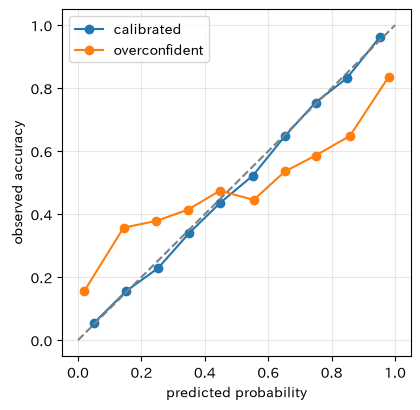

2 つのモデルの正解率（閾値 0.5）: 0.7514 0.7514


In [13]:
rng = np.random.default_rng(0)
n = 5000
p_true = rng.random(n)                                   # 本当の確率
y_obs = (rng.random(n) < p_true).astype(int)             # 実際に起きたか
p_calibrated = p_true                                    # 較正されたモデル

def logit(p):
    return np.log(p / (1 - p))                           # 確率 → ロジット（ソフトマックスの前の値．第2回）

def sigmoid(x):
    return 1 / (1 + np.exp(-x))                          # ロジット → 確率

p_over = sigmoid(3 * logit(p_true))                      # 過信するモデル：ロジットを 3 倍 → 確率が 0 や 1 に寄る

def reliability(p, y, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (p >= lo) & (p < hi)
        if m.sum() > 0:
            xs.append(p[m].mean()); ys.append(y[m].mean())
    return np.array(xs), np.array(ys)

plt.figure(figsize=(4.5, 4.5))
for name, p in (('calibrated', p_calibrated), ('overconfident', p_over)):
    xs, ys = reliability(p, y_obs)
    plt.plot(xs, ys, marker='o', label=name)
    print(f"{name:14s}: 区間ごとの (平均の予測確率, 実際の正解率) =", [f"({a:.2f}, {b:.2f})" for a, b in zip(xs, ys)])
    print(f"{'':14s}  平均の |予測確率 − 実際の正解率| = {np.mean(np.abs(xs - ys)):.3f}")
plt.plot([0, 1], [0, 1], '--', c='gray'); plt.xlabel('predicted probability'); plt.ylabel('observed accuracy'); plt.legend(); plt.grid(alpha=0.3); plt.show()
print("2 つのモデルの正解率（閾値 0.5）:", np.mean((p_calibrated >= 0.5) == y_obs), np.mean((p_over >= 0.5) == y_obs))

読み方：2 つのモデルの正解率は同じ（閾値 0.5 で答えは変わらない）が，過信するモデルは，予測確率 0.86 の区間で実際には 0.65，0.98 の区間でも 0.84 しか当たらない（低い側も，予測 0.02 の区間で実際は 0.16 起きる）．確率を意思決定に使うなら，精度とは別に較正を確かめる．

## §7 補足：実データで評価設計（FashionMNIST の分類器を点検する）

§1〜§6 の方法を，実画像（FashionMNIST）で訓練した分類器に当てる．混同行列と指標，1 クラスを「陽性」としたときの閾値と適合率・再現率，較正，複数シード，を順に見る．正解率 1 つでは見えないことを，実データで確かめる．

```{admonition} 補足節について
:class: note
ここから先は，講義で扱った構造を **実際に学習された本物のモデル** と **実画像** で動かす補足である．[torchvision](https://pytorch.org/vision/) や [Hugging Face Transformers](https://huggingface.co/docs/transformers) から学習済みモデルを取得する（初回はダウンロードに数分かかる．Colab ではインストール不要）．
手元で動かすには `pip install transformers datasets` と，インターネット接続が要る．入っていない環境では，このあとのセルは何もしない．
```

In [14]:
import os, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"; os.environ["TQDM_DISABLE"] = "1"   # ダウンロードの進捗表示を出さない
warnings.filterwarnings("ignore")
try:
    import torch
    import transformers
    import requests
    from PIL import Image
    transformers.logging.set_verbosity_error()
    HAS_HF = True
except ImportError:
    HAS_HF = False
    print("PyTorch か transformers が見つからないので，補足節のセルは何もしない（読み飛ばす）．")

def fetch_image(name):
    """COCO val2017 の画像を取得して PIL の画像で返す（ダウンロードは初回だけ．images/ に保存）"""
    import os
    os.makedirs("images", exist_ok=True)
    path = os.path.join("images", name)
    if not os.path.exists(path):
        r = requests.get("http://images.cocodataset.org/val2017/" + name, timeout=60)
        r.raise_for_status()
        open(path, "wb").write(r.content)
    return Image.open(path).convert("RGB")

COCO_IMAGES = {   # ファイル名: 内容
    "000000039769.jpg": "2 匹の猫とリモコン", "000000000285.jpg": "クマ", "000000000724.jpg": "一時停止の標識",
    "000000000776.jpg": "テディベア", "000000000785.jpg": "スキーヤー", "000000000802.jpg": "台所",
    "000000001268.jpg": "川辺と白鳥", "000000000632.jpg": "寝室",
}

In [15]:
# 補助コード：FashionMNIST（28×28 の服の画像，10 クラス）を torchvision で取得し，一部を取り出す
if HAS_HF:
    import torchvision
    from torchvision import datasets
    FASHION_CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

    def load_fashion_mnist(n_train=10000, n_test=2000, seed=0):
        """訓練 n_train 件，テスト n_test 件を無作為に取り出す．X は (n, 784)（0〜1），y は (n,)"""
        tr = datasets.FashionMNIST("data", train=True, download=True)
        te = datasets.FashionMNIST("data", train=False, download=True)
        g = torch.Generator().manual_seed(seed)
        i_tr = torch.randperm(len(tr), generator=g)[:n_train]; i_te = torch.randperm(len(te), generator=g)[:n_test]
        X_tr = tr.data[i_tr].float().div(255).reshape(-1, 784); y_tr = tr.targets[i_tr]
        X_te = te.data[i_te].float().div(255).reshape(-1, 784); y_te = te.targets[i_te]
        return X_tr, y_tr, X_te, y_te

    def show_examples(X, y, n=10):
        fig, axes = plt.subplots(1, n, figsize=(1.2 * n, 1.6))
        for k, ax in enumerate(axes):
            ax.imshow(X[k].reshape(28, 28), cmap="gray"); ax.set_title(FASHION_CLASSES[int(y[k])], fontsize=7); ax.axis("off")
        plt.show()

In [16]:
# 補助コード：隠れ層 1 つの MLP を訓練し，テストデータの予測確率を返す
if HAS_HF:
    import torch.nn as nn

    def train_classifier(X, y, seed=0, epochs=3, hidden=256, lr=0.1):
        torch.manual_seed(seed)
        model = nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, 10))
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
        for _ in range(epochs):
            perm = torch.randperm(len(X))
            for i in range(0, len(X), 128):
                idx = perm[i:i + 128]
                opt.zero_grad(); nn.functional.cross_entropy(model(X[idx]), y[idx]).backward(); opt.step()
        return model

    def predict_proba(model, X):
        with torch.no_grad():
            return model(X).softmax(dim=1).numpy()

テスト正解率 0.801


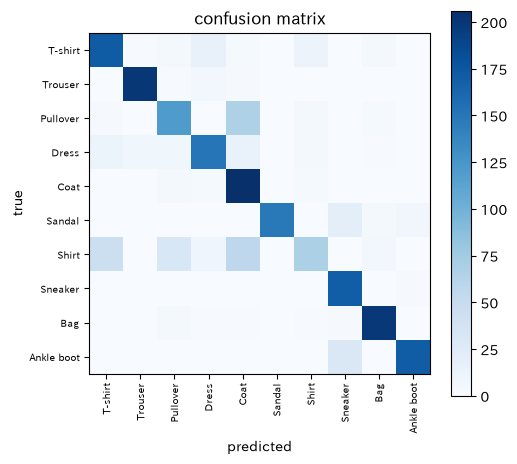

| クラス | 再現率 | 適合率 |
|    T-shirt | 0.81 | 0.75 |
|    Trouser | 0.96 | 0.96 |
|   Pullover | 0.62 | 0.69 |
|      Dress | 0.77 | 0.82 |
|       Coat | 0.95 | 0.59 |
|     Sandal | 0.83 | 1.00 |
|      Shirt | 0.31 | 0.74 |
|    Sneaker | 0.99 | 0.77 |
|        Bag | 0.96 | 0.92 |
| Ankle boot | 0.85 | 0.95 |


In [17]:
if HAS_HF:
    X_tr, y_tr, X_te, y_te = load_fashion_mnist(n_train=10000, n_test=2000)
    model = train_classifier(X_tr, y_tr)
    P = predict_proba(model, X_te); y_true = y_te.numpy(); y_pred = P.argmax(1)
    print(f"テスト正解率 {np.mean(y_pred == y_true):.3f}")
    C = np.zeros((10, 10), dtype=int)                                  # 混同行列：行が正解，列が予測
    for t, p in zip(y_true, y_pred):
        C[t, p] += 1
    plt.figure(figsize=(5.5, 5)); plt.imshow(C, cmap="Blues")
    plt.xticks(range(10), FASHION_CLASSES, rotation=90, fontsize=7); plt.yticks(range(10), FASHION_CLASSES, fontsize=7)
    plt.xlabel("predicted"); plt.ylabel("true"); plt.title("confusion matrix"); plt.colorbar(); plt.show()
    print("| クラス | 再現率 | 適合率 |")
    for c in range(10):
        rec = C[c, c] / C[c].sum(); prec = C[c, c] / max(C[:, c].sum(), 1)
        print(f"| {FASHION_CLASSES[c]:>10} | {rec:.2f} | {prec:.2f} |")

読み方：正解率は 0.8 台でも，クラスごとに見ると Shirt の再現率が低く，T-shirt・Pullover・Coat と混同している（混同行列の該当するブロック）．正解率 1 つでは「どこで間違えるか」が分からない（§1）．

次に Shirt を「陽性」とした 2 値問題にし，予測確率の閾値を動かす（§2）．

| 閾値 | 陽性と判定 | 再現率 | 適合率 |
| 0.9 |    1 | 0.00 | 1.00 |
| 0.7 |   21 | 0.09 | 0.95 |
| 0.5 |   61 | 0.24 | 0.85 |
| 0.3 |  135 | 0.44 | 0.71 |
| 0.1 |  357 | 0.77 | 0.47 |


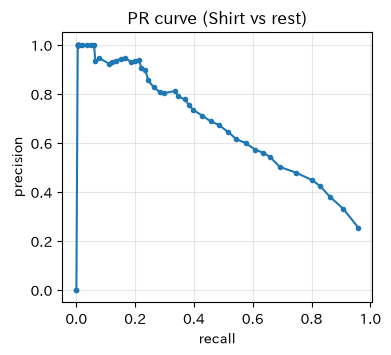

In [18]:
if HAS_HF:
    pos = 6                                                            # Shirt を陽性とする
    score = P[:, pos]; is_pos = (y_true == pos)
    print("| 閾値 | 陽性と判定 | 再現率 | 適合率 |")
    for th in (0.9, 0.7, 0.5, 0.3, 0.1):
        pred = score >= th
        tp = np.sum(pred & is_pos); rec = tp / is_pos.sum(); prec = tp / max(pred.sum(), 1)
        print(f"| {th} | {pred.sum():>4} | {rec:.2f} | {prec:.2f} |")
    ths = np.linspace(0.01, 0.99, 50)
    recs = [np.sum((score >= t) & is_pos) / is_pos.sum() for t in ths]
    precs = [np.sum((score >= t) & is_pos) / max(np.sum(score >= t), 1) for t in ths]
    plt.figure(figsize=(4, 3.5)); plt.plot(recs, precs, marker="."); plt.xlabel("recall"); plt.ylabel("precision"); plt.title("PR curve (Shirt vs rest)"); plt.grid(alpha=0.3); plt.show()

読み方：閾値を下げると再現率は上がり適合率は下がる（トレードオフ）．「Shirt を見逃したくない」なら閾値を下げ，誤警報が増えるのを受け入れる．閾値は課題の損失で決める（§2）．

較正（§6）：予測確率 0.8 のとき，本当に 8 割当たっているか．確率を 10 個の区間に分け，各区間の平均確率と実際の正解率を比べる．

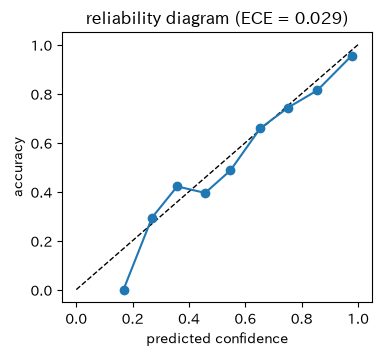

平均の確信度 0.825，正解率 0.801


In [19]:
if HAS_HF:
    conf = P.max(1); correct = (y_pred == y_true)
    bins = np.linspace(0, 1, 11); mids, accs, ece = [], [], 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.sum() == 0:
            continue
        mids.append(conf[m].mean()); accs.append(correct[m].mean()); ece += m.mean() * abs(conf[m].mean() - correct[m].mean())
    plt.figure(figsize=(4, 3.5)); plt.plot([0, 1], [0, 1], "k--", lw=1); plt.plot(mids, accs, marker="o"); plt.xlabel("predicted confidence"); plt.ylabel("accuracy"); plt.title(f"reliability diagram (ECE = {ece:.3f})"); plt.show()
    print(f"平均の確信度 {conf.mean():.3f}，正解率 {correct.mean():.3f}")

読み方：点が対角線より下なら「自信過剰」（確率が実際の正解率より高い）．ECE（期待較正誤差）はそのずれの平均．運用で確率を使うなら，温度スケーリングなどで較正してから使う（§6）．

複数シード（§5）：同じ設定で初期値と並び順だけ変えて 3 回訓練し，正解率のばらつきを見る．

In [20]:
if HAS_HF:
    accs = []
    for seed in (0, 1, 2):
        m = train_classifier(X_tr, y_tr, seed=seed)
        accs.append(float(np.mean(predict_proba(m, X_te).argmax(1) == y_true)))
    print("3 シードの正解率:", [f"{a:.3f}" for a in accs], f" 平均 {np.mean(accs):.3f} ± {np.std(accs):.3f}")

3 シードの正解率: ['0.801', '0.805', '0.818']  平均 0.808 ± 0.007


読み方：ばらつきが 0.005 程度なら，2 つの手法の差が 0.003 では「どちらが良いか」は言えない．比較には複数シードの平均とばらつきが要る（§5）．

**やってみよう 7-1**　陽性クラス `pos` を 2（Pullover）や 5（Sandal）にして，PR 曲線がどう変わるかを見る．見分けやすいクラスほど曲線は右上に張り付く．